In [3]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import glob

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [30]:
# Load dataset

df = pd.read_csv(
    '/kaggle/input/datasets/niturawat1/e-commerce-data/data.csv',
    encoding='ISO-8859-1'
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [34]:
# ==========================================
# STEP 2: LOAD DATASET
# ==========================================

file_path = '/kaggle/input/datasets/niturawat1/e-commerce-data/data.csv'

df = pd.read_csv(file_path, encoding='ISO-8859-1')

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()

Dataset loaded successfully!
Shape of dataset: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [35]:
# Check column names
print("Columns in dataset:")
print(df.columns.tolist())

Columns in dataset:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [36]:
# Statistical summary
df.describe(include='all')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,10/31/2011 14:41,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,NaN,4.611114,15287.690570,NaN
std,NaN,NaN,NaN,218.081158,NaN,96.759853,1713.600303,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN


In [37]:
print("First 5 records:")
display(df.head())

print("Last 5 records:")
display(df.tail())

First 5 records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


Last 5 records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,12680.0,France


In [39]:
rows, columns = df.shape

print("Total Rows:", rows)
print("Total Columns:", columns)

Total Rows: 541909
Total Columns: 8


In [40]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

Missing values in each column:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

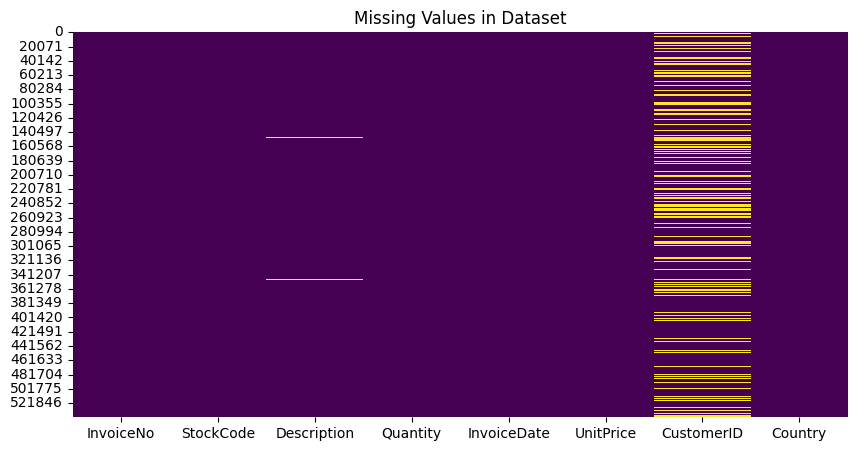

In [41]:
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), 
            cbar=False, 
            cmap='viridis')

plt.title("Missing Values in Dataset")
plt.show()

In [42]:
duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 5268


In [43]:
df[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [44]:
print("Unique Customers:", df['CustomerID'].nunique())
print("Unique Products:", df['StockCode'].nunique())
print("Unique Countries:", df['Country'].nunique())
print("Unique Invoices:", df['InvoiceNo'].nunique())

Unique Customers: 4372
Unique Products: 4070
Unique Countries: 38
Unique Invoices: 25900


In [45]:
# Create a copy of original dataset
df_clean = df.copy()

print("Working copy created.")

Working copy created.


In [46]:
df_clean.columns = df_clean.columns.str.strip()

print(df_clean.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [47]:
before_duplicates = len(df_clean)

df_clean = df_clean.drop_duplicates()

after_duplicates = len(df_clean)

print("Records before removing duplicates:", before_duplicates)
print("Records after removing duplicates:", after_duplicates)
print("Duplicates removed:", before_duplicates - after_duplicates)

Records before removing duplicates: 541909
Records after removing duplicates: 536641
Duplicates removed: 5268


In [48]:
print("Missing values before handling:")
display(df_clean.isnull().sum())

Missing values before handling:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

In [49]:
# Remove missing StockCode
df_clean = df_clean.dropna(subset=['StockCode'])

# Fill missing descriptions
df_clean['Description'] = df_clean['Description'].fillna('Unknown Product')

# Fill missing country
df_clean['Country'] = df_clean['Country'].fillna('Unknown Country')

print("Missing values handled.")

Missing values handled.


In [50]:
# CustomerID can contain missing values, so use nullable integer
df_clean['CustomerID'] = pd.to_numeric(
    df_clean['CustomerID'], errors='coerce'
).astype('Int64')

# Quantity
df_clean['Quantity'] = pd.to_numeric(
    df_clean['Quantity'], errors='coerce'
)

# Unit price
df_clean['UnitPrice'] = pd.to_numeric(
    df_clean['UnitPrice'], errors='coerce'
)

# Invoice date
df_clean['InvoiceDate'] = pd.to_datetime(
    df_clean['InvoiceDate'], errors='coerce'
)

print(df_clean.dtypes)

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              Int64
Country                object
dtype: object


In [51]:
df_clean = df_clean.dropna(subset=['InvoiceDate'])

print("Invalid dates removed.")

Invalid dates removed.


In [52]:
df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str)

df_clean['IsCancelled'] = df_clean['InvoiceNo'].str.startswith('C')

print("Cancelled transactions:", df_clean['IsCancelled'].sum())
print("Normal transactions:", (~df_clean['IsCancelled']).sum())

Cancelled transactions: 9251
Normal transactions: 527390


In [53]:
df_sales = df_clean[
    (df_clean['IsCancelled'] == False) &
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
].copy()

print("Sales dataset created.")
print("Original records:", len(df_clean))
print("Valid sales records:", len(df_sales))

Sales dataset created.
Original records: 536641
Valid sales records: 524878


In [54]:
# Outlier detection in UnitPrice

Q1 = df_sales['UnitPrice'].quantile(0.25)
Q3 = df_sales['UnitPrice'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_sales['PriceOutlier'] = (
    (df_sales['UnitPrice'] < lower_bound) |
    (df_sales['UnitPrice'] > upper_bound)
)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("Price outliers detected:", df_sales['PriceOutlier'].sum())

Q1: 1.25
Q3: 4.13
IQR: 2.88
Lower Bound: -3.0700000000000003
Upper Bound: 8.45
Price outliers detected: 37827


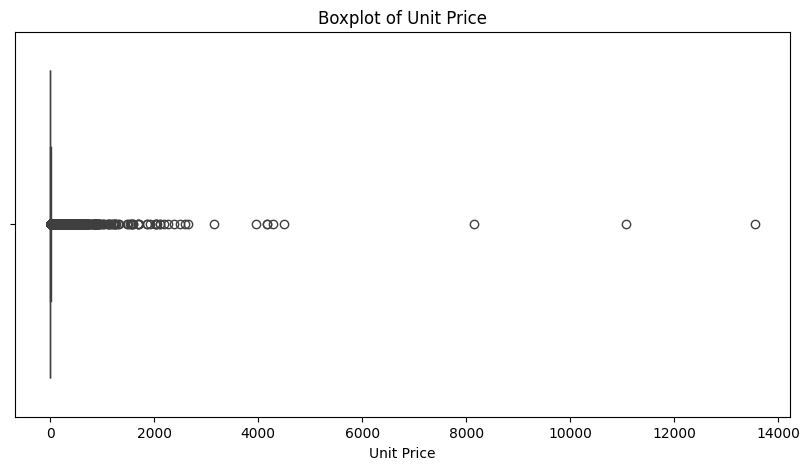

In [55]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_sales['UnitPrice'])

plt.title("Boxplot of Unit Price")
plt.xlabel("Unit Price")
plt.show()

**Data Integration**


In [15]:
customer_data = df_sales[
    ['CustomerID', 'Country']
].drop_duplicates()

customer_data = customer_data.dropna(subset=['CustomerID'])

customer_data.head()

NameError: name 'df_sales' is not defined

In [ ]:
product_data = df_sales[
    ['StockCode', 'Description', 'UnitPrice']
].drop_duplicates(subset=['StockCode'])

product_data.head()

In [ ]:
product_data = df_sales[
    ['StockCode', 'Description', 'UnitPrice']
].drop_duplicates(subset=['StockCode'])

product_data.head()

In [ ]:
integrated_data = pd.merge(
    df_sales,
    customer_data,
    on='CustomerID',
    how='left',
    suffixes=('', '_Customer')
)

print("Integrated dataset created.")
display(integrated_data.head())

In [ ]:
print("Sales dataset rows:", len(df_sales))
print("Integrated dataset rows:", len(integrated_data))

print("Missing customer IDs:", integrated_data['CustomerID'].isnull().sum())

In [16]:
# Calculate total sales amount for each transaction

df_sales['TotalAmount'] = (
    df_sales['Quantity'] * df_sales['UnitPrice']
)

print("Total sales amount calculated successfully!")

display(
    df_sales[
        ['InvoiceNo', 'StockCode', 'Quantity',
         'UnitPrice', 'TotalAmount']
    ].head(10)
)

NameError: name 'df_sales' is not defined

In [ ]:
# Calculate total sales amount for each transaction

df_sales['TotalAmount'] = (
    df_sales['Quantity'] * df_sales['UnitPrice']
)

print("Total sales amount calculated successfully!")

display(
    df_sales[
        ['InvoiceNo', 'StockCode', 'Quantity',
         'UnitPrice', 'TotalAmount']
    ].head(10)
)

In [ ]:
# Extract date and time features

df_sales['Year'] = df_sales['InvoiceDate'].dt.year

df_sales['Month'] = df_sales['InvoiceDate'].dt.month

df_sales['MonthName'] = df_sales['InvoiceDate'].dt.month_name()

df_sales['Day'] = df_sales['InvoiceDate'].dt.day

df_sales['DayName'] = df_sales['InvoiceDate'].dt.day_name()

df_sales['Hour'] = df_sales['InvoiceDate'].dt.hour

# Display extracted features

display(
    df_sales[
        ['InvoiceDate', 'Year', 'Month', 'MonthName',
         'Day', 'DayName', 'Hour']
    ].head(10)
)

print("Date and time features extracted successfully!")

In [ ]:
# Calculate customer-level purchase metrics

customer_metrics = df_sales.groupby('CustomerID').agg(
    TotalOrders=('InvoiceNo', 'nunique'),
    TotalQuantity=('Quantity', 'sum'),
    TotalRevenue=('TotalAmount', 'sum'),
    AverageOrderValue=('TotalAmount', 'mean'),
    LastPurchaseDate=('InvoiceDate', 'max')
).reset_index()

print("Customer-level metrics calculated successfully!")

display(customer_metrics.head(10))

In [17]:
# Calculate customer purchase frequency

customer_metrics['PurchaseFrequency'] = (
    customer_metrics['TotalOrders']
)

customer_metrics['AverageQuantityPerOrder'] = (
    customer_metrics['TotalQuantity'] /
    customer_metrics['TotalOrders']
)

print("Customer purchase frequency calculated successfully!")

display(customer_metrics.head(10))

NameError: name 'customer_metrics' is not defined

In [18]:
# Calculate the latest transaction date

reference_date = df_sales['InvoiceDate'].max()

# Calculate days since the customer's last purchase

customer_metrics['Recency'] = (
    reference_date - customer_metrics['LastPurchaseDate']
).dt.days

print("Customer recency calculated successfully!")

display(
    customer_metrics[
        ['CustomerID', 'LastPurchaseDate', 'Recency']
    ].head(10)
)

NameError: name 'df_sales' is not defined

In [ ]:
# Merge customer metrics with customer information

customer_data = customer_data.drop_duplicates(
    subset=['CustomerID']
)

customer_data = pd.merge(
    customer_data,
    customer_metrics,
    on='CustomerID',
    how='left'
)

print("Customer data integration completed successfully!")

display(customer_data.head(10))

print("Total customers:", len(customer_data))
print("Total columns:", len(customer_data.columns))

In [ ]:
# Calculate product-level sales metrics

product_metrics = df_sales.groupby('StockCode').agg(
    TotalUnitsSold=('Quantity', 'sum'),
    TotalRevenue=('TotalAmount', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique'),
    AverageSellingPrice=('UnitPrice', 'mean')
).reset_index()

# Integrate product information with sales metrics

product_data = pd.merge(
    product_data.drop_duplicates(subset=['StockCode']),
    product_metrics,
    on='StockCode',
    how='left'
)

print("Product-level integration completed successfully!")

display(product_data.head(10))

In [19]:
# Create time dimension table

date_data = df_sales[
    ['InvoiceDate', 'Year', 'Month', 'MonthName', 'Day', 'DayName', 'Hour']
].drop_duplicates().copy()

date_data['DateKey'] = (
    date_data['InvoiceDate'].dt.strftime('%Y%m%d').astype(int)
)

date_data = date_data.drop_duplicates(
    subset=['DateKey']
).reset_index(drop=True)

print("Time dimension table created successfully!")

display(date_data.head(10))

print("Total date records:", len(date_data))

NameError: name 'df_sales' is not defined

In [ ]:
# Create sales fact table

fact_sales = df_sales[
    [
        'InvoiceNo',
        'CustomerID',
        'StockCode',
        'InvoiceDate',
        'Quantity',
        'UnitPrice',
        'TotalAmount',
        'Year',
        'Month',
        'Day',
        'Hour'
    ]
].copy()

# Add DateKey

fact_sales['DateKey'] = (
    fact_sales['InvoiceDate'].dt.strftime('%Y%m%d').astype(int)
)

print("Sales fact table created successfully!")

display(fact_sales.head(10))

print("Total fact records:", len(fact_sales))
print("Total columns:", len(fact_sales.columns))

In [ ]:
# Generate unique CustomerKey

customer_data = customer_data.reset_index(drop=True)

customer_data['CustomerKey'] = range(
    1, len(customer_data) + 1
)

# Generate unique ProductKey

product_data = product_data.reset_index(drop=True)

product_data['ProductKey'] = range(
    1, len(product_data) + 1
)

# Generate unique DateKey if not already present

date_data = date_data.drop_duplicates(
    subset=['DateKey']
).reset_index(drop=True)

print("Dimension keys generated successfully!")

display(customer_data.head())
display(product_data.head())
display(date_data.head())

In [ ]:
# Map CustomerKey to fact table

customer_key_map = customer_data.set_index(
    'CustomerID'
)['CustomerKey']

fact_sales['CustomerKey'] = fact_sales['CustomerID'].map(
    customer_key_map
)

# Map ProductKey to fact table

product_key_map = product_data.set_index(
    'StockCode'
)['ProductKey']

fact_sales['ProductKey'] = fact_sales['StockCode'].map(
    product_key_map
)

print("Dimension keys connected to fact table successfully!")

display(fact_sales.head(10))

print("Missing CustomerKeys:", fact_sales['CustomerKey'].isnull().sum())
print("Missing ProductKeys:", fact_sales['ProductKey'].isnull().sum())

In [ ]:
# Check dimension key relationships

print("CUSTOMER KEY VALIDATION")
print("Total records:", len(fact_sales))
print("Valid CustomerKeys:", fact_sales['CustomerKey'].notnull().sum())
print("Missing CustomerKeys:", fact_sales['CustomerKey'].isnull().sum())

print("\nPRODUCT KEY VALIDATION")
print("Valid ProductKeys:", fact_sales['ProductKey'].notnull().sum())
print("Missing ProductKeys:", fact_sales['ProductKey'].isnull().sum())

print("\nDATE KEY VALIDATION")
print("Valid DateKeys:", fact_sales['DateKey'].notnull().sum())
print("Missing DateKeys:", fact_sales['DateKey'].isnull().sum())

In [20]:
# Recreate DateKey in date dimension

date_data['DateKey'] = (
    pd.to_datetime(date_data['InvoiceDate'])
    .dt.strftime('%Y%m%d')
    .astype(int)
)

# Remove duplicate dates

date_data = date_data.drop_duplicates(
    subset=['DateKey']
).reset_index(drop=True)

# Map DateKey to fact table

fact_sales['DateKey'] = (
    pd.to_datetime(fact_sales['InvoiceDate'])
    .dt.strftime('%Y%m%d')
    .astype(int)
)

print("DateKey successfully created and integrated!")

display(date_data.head())
display(fact_sales[['InvoiceNo', 'InvoiceDate', 'DateKey']].head())

NameError: name 'date_data' is not defined

In [21]:
# Select required columns for the final fact table

fact_sales = fact_sales[
    [
        'InvoiceNo',
        'CustomerKey',
        'ProductKey',
        'DateKey',
        'Quantity',
        'UnitPrice',
        'TotalAmount'
    ]
].copy()

# Remove records with missing dimension keys

fact_sales = fact_sales.dropna(
    subset=['CustomerKey', 'ProductKey', 'DateKey']
)

# Convert dimension keys to integers

fact_sales['CustomerKey'] = fact_sales['CustomerKey'].astype(int)
fact_sales['ProductKey'] = fact_sales['ProductKey'].astype(int)
fact_sales['DateKey'] = fact_sales['DateKey'].astype(int)

print("Final Fact Table Created Successfully!")

display(fact_sales.head(10))

print("Fact Table Shape:", fact_sales.shape)

NameError: name 'fact_sales' is not defined

In [22]:
# Verify all dimension and fact tables

print("========== DATA WAREHOUSE SUMMARY ==========")

print("\nFACT TABLE")
print("Fact Sales:", fact_sales.shape)

print("\nDIMENSION TABLES")
print("Customer Dimension:", customer_data.shape)
print("Product Dimension:", product_data.shape)
print("Date Dimension:", date_data.shape)

print("\nPRIMARY KEY VALIDATION")
print("Unique Customer Keys:", customer_data['CustomerKey'].nunique())
print("Unique Product Keys:", product_data['ProductKey'].nunique())
print("Unique Date Keys:", date_data['DateKey'].nunique())

print("\nFACT TABLE FOREIGN KEY VALIDATION")
print("Customer Key Matches:",
      fact_sales['CustomerKey'].isin(customer_data['CustomerKey']).all())

print("Product Key Matches:",
      fact_sales['ProductKey'].isin(product_data['ProductKey']).all())

print("Date Key Matches:",
      fact_sales['DateKey'].isin(date_data['DateKey']).all())

print("\nStar Schema verification completed!")

========== DATA WAREHOUSE SUMMARY ==========

FACT TABLE


NameError: name 'fact_sales' is not defined

In [23]:
# Discretize customer metrics into categories

customer_metrics['RecencyCategory'] = pd.qcut(
    customer_metrics['Recency'].rank(method='first'),
    q=3,
    labels=['Recent', 'Moderate', 'At Risk']
)

customer_metrics['FrequencyCategory'] = pd.qcut(
    customer_metrics['TotalOrders'].rank(method='first'),
    q=3,
    labels=['Low', 'Medium', 'High']
)

customer_metrics['MonetaryCategory'] = pd.qcut(
    customer_metrics['TotalRevenue'].rank(method='first'),
    q=3,
    labels=['Low', 'Medium', 'High']
)

print("Customer discretization completed!")

display(
    customer_metrics[
        ['CustomerID', 'Recency', 'RecencyCategory',
         'TotalOrders', 'FrequencyCategory',
         'TotalRevenue', 'MonetaryCategory']
    ].head(10)
)

NameError: name 'customer_metrics' is not defined

In [ ]:
# Merge discretized customer categories

customer_data = pd.merge(
    customer_data,
    customer_metrics[
        [
            'CustomerID',
            'RecencyCategory',
            'FrequencyCategory',
            'MonetaryCategory'
        ]
    ],
    on='CustomerID',
    how='left'
)

print("Customer segmentation integrated successfully!")

display(
    customer_data[
        [
            'CustomerID',
            'RecencyCategory',
            'FrequencyCategory',
            'MonetaryCategory'
        ]
    ].head(10)
)

In [24]:
# Check data quality across warehouse tables

print("========== DATA QUALITY REPORT ==========")

print("\n1. FACT TABLE")
print("Missing values:")
display(fact_sales.isnull().sum())

print("Duplicate records:", fact_sales.duplicated().sum())

print("\n2. CUSTOMER DIMENSION")
print("Missing values:")
display(customer_data.isnull().sum())

print("Duplicate Customer IDs:",
      customer_data['CustomerID'].duplicated().sum())

print("\n3. PRODUCT DIMENSION")
print("Missing values:")
display(product_data.isnull().sum())

print("Duplicate Product IDs:",
      product_data['StockCode'].duplicated().sum())

print("\n4. DATE DIMENSION")
print("Missing values:")
display(date_data.isnull().sum())

print("Duplicate Date Keys:",
      date_data['DateKey'].duplicated().sum())

========== DATA QUALITY REPORT ==========

1. FACT TABLE
Missing values:


NameError: name 'fact_sales' is not defined

In [ ]:
# Export all warehouse tables to CSV

fact_sales.to_csv(
    '/kaggle/working/fact_sales.csv',
    index=False
)

customer_data.to_csv(
    '/kaggle/working/dim_customer.csv',
    index=False
)

product_data.to_csv(
    '/kaggle/working/dim_product.csv',
    index=False
)

date_data.to_csv(
    '/kaggle/working/dim_date.csv',
    index=False
)

print("All Data Warehouse tables exported successfully!")

print("Files saved:")
print("1. fact_sales.csv")
print("2. dim_customer.csv")
print("3. dim_product.csv")
print("4. dim_date.csv")

In [25]:
# Perform OLAP Roll-up: Aggregate sales by year

yearly_sales = fact_sales.merge(
    date_data[['DateKey', 'Year']],
    on='DateKey',
    how='left'
)

rollup_result = yearly_sales.groupby('Year').agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique')
).reset_index()

print("OLAP Roll-up: Yearly Sales Summary")

display(rollup_result)

NameError: name 'fact_sales' is not defined

In [ ]:
# Perform OLAP Drill-down: Year-wise and month-wise sales

monthly_sales = fact_sales.merge(
    date_data[['DateKey', 'Year', 'Month', 'MonthName']],
    on='DateKey',
    how='left'
)

drilldown_result = monthly_sales.groupby(
    ['Year', 'Month', 'MonthName']
).agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique')
).reset_index()

drilldown_result = drilldown_result.sort_values(
    ['Year', 'Month']
)

print("OLAP Drill-down: Monthly Sales Summary")

display(drilldown_result)

In [26]:
# Select one year for OLAP Slice operation

selected_year = fact_sales.merge(
    date_data[['DateKey', 'Year']],
    on='DateKey',
    how='left'
)

selected_year = selected_year['Year'].max()

slice_result = monthly_sales[
    monthly_sales['Year'] == selected_year
]

slice_result = slice_result.groupby(
    ['Month', 'MonthName']
).agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique')
).reset_index()

slice_result = slice_result.sort_values('Month')

print("OLAP Slice Operation")
print("Selected Year:", selected_year)

display(slice_result)

NameError: name 'fact_sales' is not defined

In [27]:
# Perform OLAP Dice using multiple conditions

dice_result = monthly_sales[
    (monthly_sales['Year'] == selected_year) &
    (monthly_sales['Month'].isin([1, 2, 3])) &
    (monthly_sales['TotalAmount'] > 100)
]

dice_summary = dice_result.groupby(
    ['Year', 'Month']
).agg(
    TotalRevenue=('TotalAmount', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    TotalTransactions=('InvoiceNo', 'nunique')
).reset_index()

print("OLAP Dice Operation")
print("Selected Year:", selected_year)
print("Selected Months: January, February, March")
print("Minimum transaction amount: 100")

display(dice_summary)

NameError: name 'monthly_sales' is not defined

In [28]:
# Perform OLAP Pivot operation

pivot_result = monthly_sales.pivot_table(
    index='Year',
    columns='MonthName',
    values='TotalAmount',
    aggfunc='sum',
    fill_value=0
)

# Arrange months chronologically

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

pivot_result = pivot_result.reindex(
    columns=month_order,
    fill_value=0
)

print("OLAP Pivot Operation: Year-wise Monthly Revenue")

display(pivot_result)

NameError: name 'monthly_sales' is not defined

In [ ]:
# Define observation and prediction periods

reference_date = df_sales['InvoiceDate'].max()

cutoff_date = reference_date - pd.Timedelta(days=90)

# Historical customer data (before cutoff date)

historical_data = df_sales[
    (df_sales['InvoiceDate'] < cutoff_date) &
    (df_sales['CustomerID'].notnull())
].copy()

# Future customer activity (next 90 days)

future_data = df_sales[
    (df_sales['InvoiceDate'] >= cutoff_date) &
    (df_sales['InvoiceDate'] <= reference_date) &
    (df_sales['CustomerID'].notnull())
].copy()

# Generate customer features

churn_features = historical_data.groupby('CustomerID').agg(
    TotalOrders=('InvoiceNo', 'nunique'),
    TotalQuantity=('Quantity', 'sum'),
    TotalRevenue=('TotalAmount', 'sum'),
    AverageOrderValue=('TotalAmount', 'mean'),
    AverageUnitPrice=('UnitPrice', 'mean'),
    LastPurchaseDate=('InvoiceDate', 'max')
).reset_index()

# Calculate recency

churn_features['Recency'] = (
    cutoff_date - churn_features['LastPurchaseDate']
).dt.days

# Calculate future purchases

future_customers = future_data.groupby('CustomerID').agg(
    FutureOrders=('InvoiceNo', 'nunique')
).reset_index()

# Merge future activity

churn_features = churn_features.merge(
    future_customers,
    on='CustomerID',
    how='left'
)

churn_features['FutureOrders'] = (
    churn_features['FutureOrders'].fillna(0)
)

# Generate churn labels
# 1 = Churned, 0 = Active

churn_features['Churn'] = (
    churn_features['FutureOrders'] == 0
).astype(int)

print("Churn prediction dataset created successfully!")

display(churn_features.head(10))

print("\nTotal customers:", len(churn_features))
print("Churned customers:", churn_features['Churn'].sum())
print("Active customers:", (churn_features['Churn'] == 0).sum())

In [ ]:
from sklearn.model_selection import train_test_split

# Select features for machine learning

features = [
    'TotalOrders',
    'TotalQuantity',
    'TotalRevenue',
    'AverageOrderValue',
    'AverageUnitPrice',
    'Recency'
]

X = churn_features[features]

y = churn_features['Churn']

# Split dataset: 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset split completed successfully!")

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    class_weight='balanced'
)

# Train the model

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

In [ ]:
# Predict customer churn on test data

y_pred = rf_model.predict(X_test)

# Predict churn probabilities

y_pred_probability = rf_model.predict_proba(X_test)[:, 1]

print("Customer churn predictions generated successfully!")

results = pd.DataFrame({
    'Actual_Churn': y_test.values,
    'Predicted_Churn': y_pred,
    'Churn_Probability': y_pred_probability
})

display(results.head(15))

In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

roc_auc = roc_auc_score(y_test, y_pred_probability)

# Display results

print("========== MODEL EVALUATION ==========")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")
print("ROC-AUC Score:", round(roc_auc, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

NameError: name 'y_test' is not defined